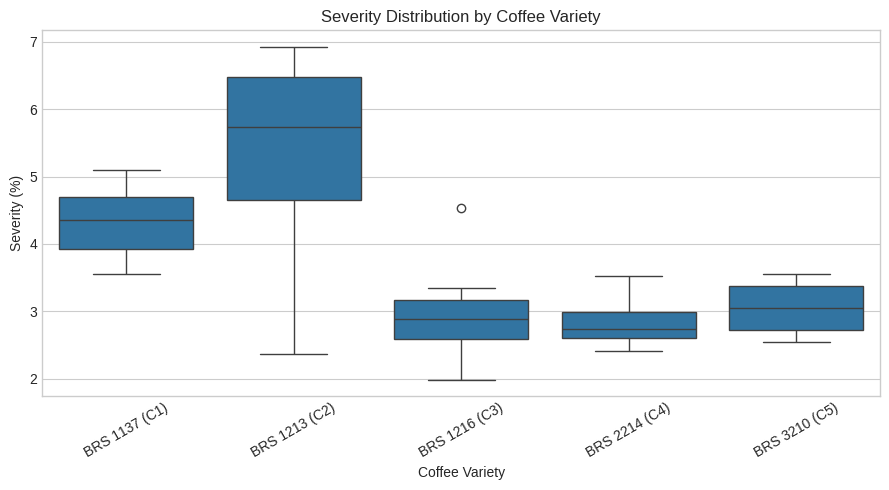

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ============================
# LOAD CSV (LOCAL / COLAB)
# ============================

# Corrected path: The file is located in /content/, not /mnt/data/

path = "/content/Severidade  - Página1 (2).csv"
df = pd.read_csv(path)

# ============================
# STANDARDIZE COLUMN NAMES
# ============================

column_mapping = {
    'porcentagem_area_afetada': 'severity_percentage',
    'Severidade (%)': 'severity_percentage',
    'variedade_cafe': 'coffee_variety',
    'Variedade de Café': 'coffee_variety'
}

df.rename(columns=column_mapping, inplace=True)

# ============================
# DATA CLEANING
# ============================

df['severity_percentage'] = (
    df['severity_percentage']
    .astype(str)
    .str.replace(',', '.', regex=False)
    .astype(float)
)

df = df.dropna(subset=['severity_percentage', 'coffee_variety'])

# ============================
# BOXPLOT
# ============================

plt.figure(figsize=(9, 5))
sns.boxplot(
    data=df,
    x='coffee_variety',
    y='severity_percentage'
)

plt.xlabel('Coffee Variety')
plt.ylabel('Severity (%)')
plt.title('Severity Distribution by Coffee Variety')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()